<a href="https://colab.research.google.com/github/arnolosabas/Seminario-de-Investigacion/blob/main/Codigo_Seminario_Investigacion_modificado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de entropía de von Neumann en árboles

Este cuaderno busca pares de árboles no isomorfos del mismo orden con entropías de von Neumann muy cercanas y espectros laplacianos numéricamente distintos. Además, resume las diferencias entre sus propiedades estructurales.

In [1]:
import os
import json
from collections import deque

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Parámetros del experimento
NUM_VERTICES = 20
EPS_ENTROPIA = 1e-10
EPS_ESPECTRO = 1e-10
TOL_CERO = 1e-12
CARPETA_SALIDA = "resultados_seminario"

os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("NetworkX:", nx.__version__)
print("Orden de los árboles:", NUM_VERTICES)
print("Tolerancia de entropía:", EPS_ENTROPIA)
print("Tolerancia para comparar espectros:", EPS_ESPECTRO)

NetworkX: 3.7
Orden de los árboles: 20
Tolerancia de entropía: 1e-10
Tolerancia para comparar espectros: 1e-10


## 1. Funciones para calcular el espectro y la entropía

Para un árbol de orden `n`, se utiliza la matriz laplaciana `L = D - A`. Como un árbol tiene `n-1` aristas, la normalización es `Tr(L)=2(n-1)`. La entropía se calcula con logaritmos en base 2.

In [2]:
def laplaciano(G):
    """Devuelve la matriz laplaciana de G como una matriz NumPy real."""
    return nx.laplacian_matrix(G).toarray().astype(float)


def espectro_laplaciano(G):
    """Calcula los autovalores laplacianos en orden creciente."""
    valores = np.linalg.eigvalsh(laplaciano(G))
    valores[np.abs(valores) < TOL_CERO] = 0.0
    return valores


def entropia_desde_espectro(espectro, n):
    """Calcula la entropía de von Neumann del espectro laplaciano."""
    normalizacion = 2 * (n - 1)
    p = np.asarray(espectro, dtype=float) / normalizacion
    p = p[p > TOL_CERO]
    return float(-np.sum(p * np.log2(p)))


def codigo_arbol(T):
    """Codificación graph6 sin encabezado, útil para guardar/reconstruir el árbol."""
    return nx.to_graph6_bytes(T, header=False).decode("ascii").strip()


def arbol_desde_codigo(codigo):
    """Reconstruye un árbol a partir de su código graph6."""
    return nx.from_graph6_bytes(codigo.encode("ascii"))


def son_cospectrales(espectro1, espectro2, tol=EPS_ESPECTRO):
    """True si los espectros coinciden dentro de la tolerancia indicada."""
    return np.allclose(espectro1, espectro2, atol=tol, rtol=0.0)


def son_eps_coentropicos(S1, S2, eps=EPS_ENTROPIA):
    """Cercanía numérica de entropías; no implica igualdad matemática exacta."""
    return abs(S1 - S2) <= eps

## 2. Búsqueda de pares candidatos

Para reducir el consumo de memoria, durante el recorrido se guarda el código del árbol y su entropía, pero no se conserva el espectro de todos los árboles. Después de ordenar los datos por entropía, solo se recalculan los espectros de los pares que satisfacen el umbral de cercanía.

La función devuelve los pares que son candidatos a coentrópicos y cuyos espectros no coinciden dentro de `EPS_ESPECTRO`. Los índices son los índices de la enumeración de `nx.nonisomorphic_trees(n)` y no son invariantes matemáticos.

In [3]:
def buscar_candidatos(n, tol_entropia=EPS_ENTROPIA, tol_espectro=EPS_ESPECTRO,
                      mostrar_progreso=True):
    """Busca pares de árboles no isomorfos con entropías iguales y espectros distintos."""
    datos = []
    total = 0

    for indice, T in enumerate(nx.nonisomorphic_trees(n)):
        codigo = codigo_arbol(T)
        espectro = espectro_laplaciano(T)
        S = entropia_desde_espectro(espectro, n)
        datos.append({"indice": indice, "codigo": codigo, "entropia": S})
        total += 1

        if mostrar_progreso and total % 100000 == 0:
            print(f"Árboles procesados: {total:,}")

    datos.sort(key=lambda x: x["entropia"])
    candidatos = []
    cache_espectros = {}

    def espectro_por_codigo(codigo):
        if codigo not in cache_espectros:
            cache_espectros[codigo] = espectro_laplaciano(arbol_desde_codigo(codigo))
        return cache_espectros[codigo]

    for i in range(len(datos)):
        j = i + 1
        while j < len(datos):
            diferencia = datos[j]["entropia"] - datos[i]["entropia"]
            if diferencia > tol_entropia:
                break

            d1, d2 = datos[i], datos[j]
            e1 = espectro_por_codigo(d1["codigo"])
            e2 = espectro_por_codigo(d2["codigo"])

            if not son_cospectrales(e1, e2, tol_espectro):
                candidatos.append({
                    "indice1": d1["indice"],
                    "indice2": d2["indice"],
                    "codigo1": d1["codigo"],
                    "codigo2": d2["codigo"],
                    "entropia1": d1["entropia"],
                    "entropia2": d2["entropia"],
                    "diferencia": abs(d2["entropia"] - d1["entropia"]),
                    "espectro1": e1.copy(),
                    "espectro2": e2.copy(),
                })
            j += 1

    # Se conserva el orden de enumeración de los pares para que los identificadores
    # coincidan con la versión anterior del cuaderno. La tabla ordenada por ΔS se
    # construye más adelante sin cambiar esos identificadores.
    print(f"Total de árboles no isomorfos de orden {n}: {total:,}")
    print(f"Pares candidatos encontrados: {len(candidatos):,}")
    return candidatos

## 3. Propiedades estructurales y momentos laplacianos


In [4]:
def propiedades_estructurales(codigo):
    T = arbol_desde_codigo(codigo)
    n = T.number_of_nodes()
    grados = sorted((d for _, d in T.degree()), reverse=True)
    grados_dict = dict(T.degree())

    zagreb1 = int(sum(d**2 for d in grados))
    suma_grados_cubo = int(sum(d**3 for d in grados))
    zagreb2 = int(sum(grados_dict[u] * grados_dict[v] for u, v in T.edges()))
    wiener = int(nx.wiener_index(T))

    L_entera = nx.laplacian_matrix(T).toarray().astype(np.int64)
    espectro = np.linalg.eigvalsh(L_entera.astype(float))
    espectro[np.abs(espectro) < TOL_CERO] = 0.0

    momentos = {
        f"momento{k}": int(np.trace(np.linalg.matrix_power(L_entera, k)))
        for k in (2, 3, 4)
    }

    return {
        "n": n,
        "espectro": espectro,
        "grados": grados,
        "grado_maximo": max(grados),
        "hojas": sum(d == 1 for d in grados),
        "diametro": int(nx.diameter(T)),
        "radio": int(nx.radius(T)),
        "wiener": wiener,
        "zagreb1": zagreb1,
        "suma_grados_cubo": suma_grados_cubo,
        "zagreb2": zagreb2,
        "lambda2": float(espectro[1]),
        "lambda_max": float(espectro[-1]),
        **momentos,
    }

## 4. Ejecutar la búsqueda


In [5]:
# Ejecutar una vez para el experimento principal.
candidatos = buscar_candidatos(NUM_VERTICES)

Árboles procesados: 100,000
Árboles procesados: 200,000
Árboles procesados: 300,000
Árboles procesados: 400,000
Árboles procesados: 500,000
Árboles procesados: 600,000
Árboles procesados: 700,000
Árboles procesados: 800,000
Total de árboles no isomorfos de orden 20: 823,065
Pares candidatos encontrados: 442


## 5. Construir las tablas de comparación

Se calculan las propiedades de cada árbol una sola vez y se reutilizan cuando aparecen en más de un par.

In [6]:
cache_propiedades = {}

def propiedades_cached(codigo):
    if codigo not in cache_propiedades:
        cache_propiedades[codigo] = propiedades_estructurales(codigo)
    return cache_propiedades[codigo]
propiedades_comparadas = [
    "grados", "grado_maximo", "hojas", "diametro", "radio", "wiener",
    "zagreb1", "zagreb2", "lambda2", "lambda_max", "momento2", "momento3", "momento4"
]
filas = []
for k, c in enumerate(candidatos, start=1):
    p1 = propiedades_cached(c["codigo1"])
    p2 = propiedades_cached(c["codigo2"])

    fila = {
        "candidato": k,
        "indice1": c["indice1"],
        "indice2": c["indice2"],
        "codigo1": c["codigo1"],
        "codigo2": c["codigo2"],
        "entropia1": c["entropia1"],
        "entropia2": c["entropia2"],
        "delta_entropia": c["diferencia"],
    }

    for prop in propiedades_comparadas:
        fila[f"{prop}_T1"] = str(p1[prop]) if prop == "grados" else p1[prop]
        fila[f"{prop}_T2"] = str(p2[prop]) if prop == "grados" else p2[prop]
        if prop in ("lambda2", "lambda_max"):
            iguales = np.isclose(p1[prop], p2[prop], atol=EPS_ESPECTRO, rtol=0.0)
        else:
            iguales = p1[prop] == p2[prop]
        fila[f"{prop}_iguales"] = bool(iguales)
        if prop != "grados":
            fila[f"delta_{prop}"] = abs(p1[prop] - p2[prop])

    filas.append(fila)

if filas:
    pares_df = pd.DataFrame(filas)
else:
    columnas = ["candidato", "indice1", "indice2", "codigo1", "codigo2",
                "entropia1", "entropia2", "delta_entropia"]
    for prop in propiedades_comparadas:
        columnas.extend([f"{prop}_T1", f"{prop}_T2", f"{prop}_iguales"])
        if prop != "grados":
            columnas.append(f"delta_{prop}")
    pares_df = pd.DataFrame(columns=columnas)

pares_ordenados_df = pares_df.sort_values("delta_entropia", ascending=True).reset_index(drop=True)
print(f"Pares en la tabla: {len(pares_df)}")
display(pares_df.head())

Pares en la tabla: 442


,candidato,indice1,indice2,codigo1,codigo2,entropia1,entropia2,delta_entropia,grados_T1,grados_T2,...,momento2_iguales,delta_momento2,momento3_T1,momento3_T2,momento3_iguales,delta_momento3,momento4_T1,momento4_T2,momento4_iguales,delta_momento4
0,1,770336,802562,SpE?I?@?G@?G?@?O?G?A??O@??A??A???,SpGc?D??G?_C?G?G?C?@?O????G??O??O,3.600618,3.600618,4.292122e-11,"[7, 5, 3, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, ...","[7, 4, 4, 3, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, ...",...,True,0,926,914,False,12,6354,6086,False,268
1,2,527239,514618,SpCO__OGC?G??@??_?G?CO?@??A??A???,SpCI?C@?G@?O?_O???I??O?@??A??A???,3.601801,3.601801,5.517720e-11,"[6, 6, 3, 3, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, ...","[8, 4, 3, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, ...",...,False,4,902,1034,False,132,5786,7990,False,2204
2,3,579140,719258,SpCOc?@?K??@_?_?O?C??O????G??G??C,SpC`@A?_C?G??@??_?O?G??D??A??A???,3.614200,3.614200,4.909761e-11,"[8, 4, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, ...","[5, 5, 5, 3, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, ...",...,False,8,1016,800,False,216,7848,4684,False,3164
3,4,737276,817050,SpCc?CA?_CG??@??_?O?C??`??A??A???,SpH?GCC@?GG??@?@??a????C??O??a???,3.620699,3.620699,9.444445e-11,"[5, 5, 5, 3, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, ...","[5, 5, 4, 4, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, ...",...,False,2,800,770,False,30,4604,4382,False,222
4,5,564088,800774,SpCO`?_GA??@?@?A??G?O??C?G??OA???,SpGc?E??K?G??@?@??_?GO????G??O??O,3.622018,3.622018,1.472511e-11,"[6, 5, 4, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, ...","[5, 5, 4, 4, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, ...",...,False,2,818,770,False,48,4980,4350,False,630


## 6. Resumen de coincidencias y diferencias

La tabla cuenta, para cada propiedad, cuántos pares tienen el mismo valor y cuántos tienen valores distintos. Las comparaciones de `lambda2` y `lambda_max` se hacen con la tolerancia espectral indicada.

In [7]:
propiedades_resumen = [
    ("Secuencia de grados", "grados_iguales"),
    ("Grado máximo", "grado_maximo_iguales"),
    ("Número de hojas", "hojas_iguales"),
    ("Diámetro", "diametro_iguales"),
    ("Radio", "radio_iguales"),
    ("Índice de Wiener", "wiener_iguales"),
    ("Primer índice de Zagreb", "zagreb1_iguales"),
    ("Segundo índice de Zagreb", "zagreb2_iguales"),
    ("Autovalor lambda_2", "lambda2_iguales"),
    ("Autovalor máximo", "lambda_max_iguales"),
    ("Momento laplaciano 2", "momento2_iguales"),
    ("Momento laplaciano 3", "momento3_iguales"),
    ("Momento laplaciano 4", "momento4_iguales"),
]

n_pares = len(pares_df)
resumen_filas = []
for nombre, columna in propiedades_resumen:
    iguales = int(pares_df[columna].sum()) if n_pares else 0
    distintos = n_pares - iguales
    resumen_filas.append({
        "propiedad": nombre,
        "pares_iguales": iguales,
        "pares_distintos": distintos,
        "porcentaje_distintos": (100 * distintos / n_pares) if n_pares else 0.0,
        "total_pares": n_pares,
    })

resumen_df = pd.DataFrame(resumen_filas)
display(resumen_df)

,propiedad,pares_iguales,pares_distintos,porcentaje_distintos,total_pares
0,Secuencia de grados,166,276,62.443439,442
1,Grado máximo,252,190,42.986425,442
2,Número de hojas,234,208,47.058824,442
3,Diámetro,109,333,75.339367,442
4,Radio,197,245,55.429864,442
5,Índice de Wiener,2,440,99.547511,442
6,Primer índice de Zagreb,282,160,36.199095,442
7,Segundo índice de Zagreb,60,382,86.425339,442
8,Autovalor lambda_2,0,442,100.000000,442
9,Autovalor máximo,0,442,100.000000,442


## 6b. Resumen de las diferencias de entropía

Esta tabla resume la escala de las diferencias de entropía, incluyendo cuántos pares caen bajo tolerancias más estrictas. Aunque los pares se seleccionan usando `EPS_ENTROPIA`, los umbrales más pequeños ayudan a describir la distribución de los resultados.

In [8]:
if n_pares:
    ds = pares_df["delta_entropia"].astype(float)
    resumen_entropia_df = pd.DataFrame([{
        "total_pares": n_pares,
        "minimo_delta_S": float(ds.min()),
        "mediana_delta_S": float(ds.median()),
        "media_delta_S": float(ds.mean()),
        "maximo_delta_S": float(ds.max()),
        "pares_delta_S_le_1e-12": int((ds <= 1e-12).sum()),
        "pares_delta_S_le_1e-11": int((ds <= 1e-11).sum()),
        "pares_delta_S_le_EPS_ENTROPIA": int((ds <= EPS_ENTROPIA).sum()),
        "pares_delta_S_exactamente_cero_en_float": int((ds == 0.0).sum()),
    }])
else:
    resumen_entropia_df = pd.DataFrame([{
        "total_pares": 0, "minimo_delta_S": np.nan, "mediana_delta_S": np.nan,
        "media_delta_S": np.nan, "maximo_delta_S": np.nan,
        "pares_delta_S_le_1e-12": 0, "pares_delta_S_le_1e-11": 0,
        "pares_delta_S_le_EPS_ENTROPIA": 0,
        "pares_delta_S_exactamente_cero_en_float": 0,
    }])
display(resumen_entropia_df)

,total_pares,minimo_delta_S,mediana_delta_S,media_delta_S,maximo_delta_S,pares_delta_S_le_1e-12,pares_delta_S_le_1e-11,pares_delta_S_le_EPS_ENTROPIA,pares_delta_S_exactamente_cero_en_float
0,442,5.329071e-15,4.718270e-11,4.907979e-11,9.989432e-11,5,45,442,0


## 7. Pares con la misma secuencia de grados

Este subconjunto permite estudiar si compartir la distribución de grados implica compartir otras características. No implica, en general, que los árboles sean isomorfos.

In [9]:
misma_secuencia_df = pares_df.loc[pares_df["grados_iguales"].astype(bool)].copy()

print("Pares con la misma secuencia de grados:", len(misma_secuencia_df))
for nombre, columna in [
    ("Índice de Wiener", "wiener_iguales"),
    ("Diámetro", "diametro_iguales"),
    ("Radio", "radio_iguales"),
    ("Segundo índice de Zagreb", "zagreb2_iguales"),
    ("Momento laplaciano 4", "momento4_iguales"),
]:
    distintos = int((~misma_secuencia_df[columna].astype(bool)).sum())
    print(f"{nombre}: {distintos} de {len(misma_secuencia_df)} pares tienen valores distintos")

display(misma_secuencia_df[[
    "candidato", "indice1", "indice2", "delta_entropia",
    "diametro_T1", "diametro_T2", "wiener_T1", "wiener_T2",
    "zagreb2_T1", "zagreb2_T2"
]].head(20))

Pares con la misma secuencia de grados: 166
Índice de Wiener: 165 de 166 pares tienen valores distintos
Diámetro: 103 de 166 pares tienen valores distintos
Radio: 66 de 166 pares tienen valores distintos
Segundo índice de Zagreb: 123 de 166 pares tienen valores distintos
Momento laplaciano 4: 123 de 166 pares tienen valores distintos


,candidato,indice1,indice2,delta_entropia,diametro_T1,diametro_T2,wiener_T1,wiener_T2,zagreb2_T1,zagreb2_T2
5,6,779837,786831,4.939604e-12,7,6,696,684,133,132
20,21,663378,705886,3.850253e-11,8,8,695,693,127,127
25,26,361213,535800,9.731771e-12,9,7,738,713,124,123
27,28,537806,761121,1.326939e-12,8,7,748,709,120,116
29,30,356543,552759,4.462031e-11,10,8,773,742,127,122
39,40,632491,569513,8.653833e-11,7,8,701,714,120,122
47,48,615477,596294,8.632206e-12,7,7,721,724,115,117
51,52,489365,710919,2.717337e-11,9,8,689,695,129,128
52,53,724637,696670,4.379741e-11,8,7,677,667,129,127
55,56,654806,505029,2.178924e-11,8,9,699,723,125,124


## 8. Selección automática de ejemplos representativos


In [10]:
def fila_candidato_por_indice(indice_candidato):
    return pares_df.loc[pares_df["candidato"] == indice_candidato].iloc[0]

seleccion = []
def agregar_ejemplo(fila, motivo):
    if fila is None:
        return
    cid = int(fila["candidato"])
    if all(int(x["candidato"]) != cid for x in seleccion):
        d = fila.to_dict()
        d["motivo_seleccion"] = motivo
        seleccion.append(d)

if not pares_df.empty:
    agregar_ejemplo(pares_df.loc[pares_df["delta_entropia"].idxmin()],
                    "Menor diferencia de entropía; verificar precisión numérica")
    agregar_ejemplo(pares_df.loc[pares_df["delta_diametro"].idxmax()],
                    "Mayor diferencia de diámetro")
    agregar_ejemplo(pares_df.loc[pares_df["delta_wiener"].idxmax()],
                    "Mayor diferencia absoluta del índice de Wiener")

    filtro = pares_df[
        pares_df["grados_iguales"] & pares_df["wiener_iguales"] & (~pares_df["diametro_iguales"])
    ]
    if not filtro.empty:
        agregar_ejemplo(filtro.loc[filtro["delta_entropia"].idxmin()],
                        "Misma secuencia de grados y mismo Wiener, pero diámetro distinto")

    filtro = pares_df[pares_df["grados_iguales"] & (~pares_df["wiener_iguales"])]
    if not filtro.empty:
        agregar_ejemplo(filtro.loc[filtro["delta_entropia"].idxmin()],
                        "Misma secuencia de grados, pero Wiener distinto")

ejemplos_df = pd.DataFrame(seleccion)
if not ejemplos_df.empty:
    display(ejemplos_df[[
        "motivo_seleccion", "candidato", "indice1", "indice2", "delta_entropia",
        "grados_T1", "grados_T2", "diametro_T1", "diametro_T2",
        "wiener_T1", "wiener_T2", "zagreb1_T1", "zagreb1_T2",
        "zagreb2_T1", "zagreb2_T2", "lambda2_T1", "lambda2_T2",
        "lambda_max_T1", "lambda_max_T2"
    ]])

,motivo_seleccion,candidato,indice1,indice2,delta_entropia,grados_T1,grados_T2,diametro_T1,diametro_T2,wiener_T1,wiener_T2,zagreb1_T1,zagreb1_T2,zagreb2_T1,zagreb2_T2,lambda2_T1,lambda2_T2,lambda_max_T1,lambda_max_T2
0,Menor diferencia de entropía; verificar precis...,221,220221,458315,5.329071e-15,"[4, 4, 3, 3, 3, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1, ...","[4, 4, 3, 3, 3, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1, ...",9,9,790,782,94,94,104,105,0.060066,0.069304,5.488044,5.626513
1,Mayor diferencia de diámetro,322,755895,24800,4.704370e-11,"[4, 4, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, ...","[5, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, ...",7,13,739,945,90,92,103,100,0.084832,0.039507,5.587609,6.194866
2,Mayor diferencia absoluta del índice de Wiener,289,447131,15976,4.367218e-11,"[5, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, ...","[5, 4, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, ...",9,13,753,1024,92,94,107,101,0.075982,0.032544,6.295973,6.192066
3,"Misma secuencia de grados y mismo Wiener, pero...",380,447663,427098,2.624079e-11,"[4, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, ...","[4, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, ...",10,9,831,831,88,88,97,96,0.067347,0.061165,5.487299,5.297498


## 9. Exportar tablas

Se guardan las tablas en CSV y en un libro Excel con hojas separadas. Los archivos se crean en `resultados_seminario/`.

In [11]:
# CSV:
resumen_df.to_csv(f"{CARPETA_SALIDA}/resumen_propiedades.csv", index=False, encoding="utf-8-sig")
resumen_entropia_df.to_csv(f"{CARPETA_SALIDA}/resumen_entropia.csv", index=False, encoding="utf-8-sig")
pares_df.to_csv(f"{CARPETA_SALIDA}/pares_detallados.csv", index=False, encoding="utf-8-sig")
pares_ordenados_df.to_csv(f"{CARPETA_SALIDA}/pares_ordenados_por_deltaS.csv", index=False, encoding="utf-8-sig")
misma_secuencia_df.to_csv(f"{CARPETA_SALIDA}/pares_misma_secuencia_grados.csv", index=False, encoding="utf-8-sig")
ejemplos_df.to_csv(f"{CARPETA_SALIDA}/ejemplos_representativos.csv", index=False, encoding="utf-8-sig")

# Excel:
ruta_excel = f"{CARPETA_SALIDA}/resultados_resumen_orden_{NUM_VERTICES}.xlsx"
with pd.ExcelWriter(ruta_excel) as writer:
    resumen_df.to_excel(writer, sheet_name="Resumen", index=False)
    resumen_entropia_df.to_excel(writer, sheet_name="Resumen_entropia", index=False)
    pares_df.to_excel(writer, sheet_name="Pares", index=False)
    pares_ordenados_df.to_excel(writer, sheet_name="Pares_ordenados", index=False)
    misma_secuencia_df.to_excel(writer, sheet_name="Misma_secuencia", index=False)
    ejemplos_df.to_excel(writer, sheet_name="Ejemplos", index=False)

print("Archivos guardados en:", os.path.abspath(CARPETA_SALIDA))
print("Libro Excel:", os.path.abspath(ruta_excel))

Archivos guardados en: /content/resultados_seminario
Libro Excel: /content/resultados_seminario/resultados_resumen_orden_20.xlsx


## 10. Gráficos de resumen

El primer gráfico presenta la distribución de las diferencias de entropía en escala logarítmica. El segundo compara el número de pares que difieren en algunas propiedades estructurales.

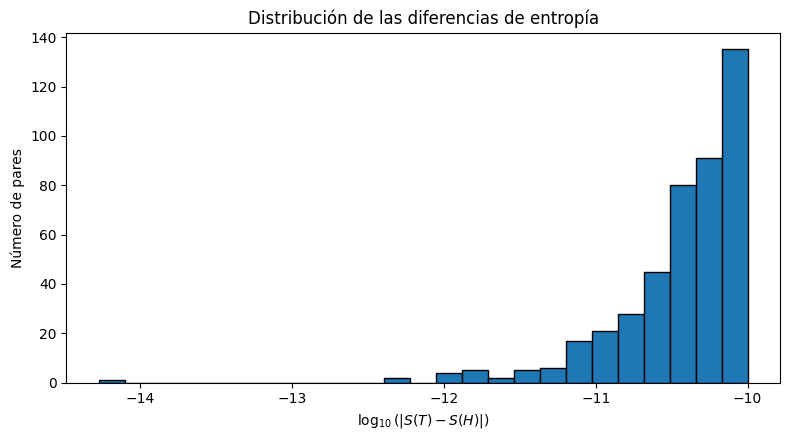

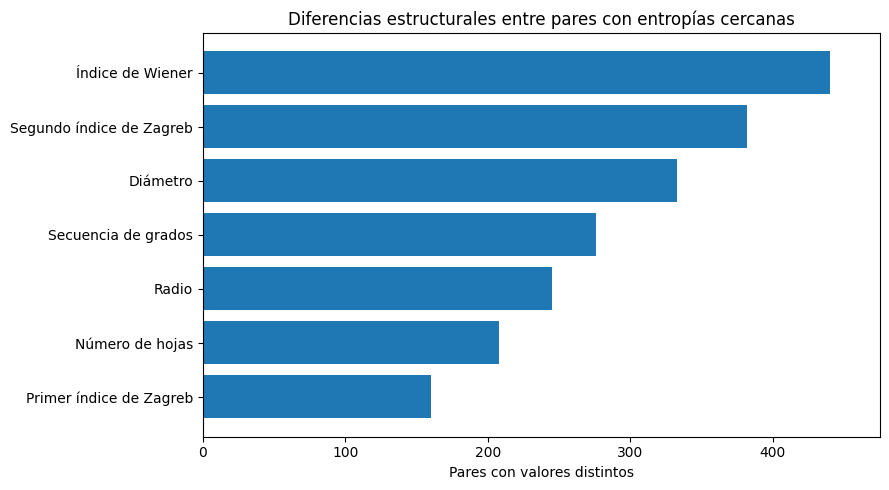

In [12]:
if not pares_df.empty:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    valores_log = np.log10(pares_df["delta_entropia"].clip(lower=np.finfo(float).tiny))
    ax.hist(valores_log, bins=25, edgecolor="black")
    ax.set_xlabel(r"$\log_{10}(|S(T)-S(H)|)$")
    ax.set_ylabel("Número de pares")
    ax.set_title("Distribución de las diferencias de entropía")
    fig.tight_layout()
    fig.savefig(f"{CARPETA_SALIDA}/histograma_delta_entropia.png", dpi=200, bbox_inches="tight")
    plt.show()

    resumen_grafico = resumen_df[resumen_df["propiedad"].isin([
        "Índice de Wiener", "Diámetro", "Radio", "Número de hojas",
        "Secuencia de grados", "Primer índice de Zagreb", "Segundo índice de Zagreb"
    ])].sort_values("pares_distintos")

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(resumen_grafico["propiedad"], resumen_grafico["pares_distintos"])
    ax.set_xlabel("Pares con valores distintos")
    ax.set_title("Diferencias estructurales entre pares con entropías cercanas")
    ax.set_xlim(0, max(resumen_grafico["pares_distintos"].max() * 1.08, 1))
    fig.tight_layout()
    fig.savefig(f"{CARPETA_SALIDA}/propiedades_distintas.png", dpi=200, bbox_inches="tight")
    plt.show()

## 11. Dibujar un par seleccionado (opcional)

No se dibujan automáticamente todos los pares: pueden ser cientos de figuras. Para visualizar uno, usa `dibujar_candidato(candidatos[k])`, donde `k` empieza en cero. La figura puede guardarse indicando `guardar=True`.

In [13]:
def layout_arbol_jerarquico(T, raiz=None, ancho=2.0, nivel_y=1.8):
    if raiz is None:
        raiz = nx.center(T)[0]
    parent = {raiz: None}
    niveles = {0: [raiz]}
    cola = deque([(raiz, 0)])

    while cola:
        u, nivel = cola.popleft()
        hijos = []
        for v in sorted(T.neighbors(u)):
            if v != parent[u]:
                parent[v] = u
                hijos.append(v)
        if hijos:
            niveles.setdefault(nivel + 1, []).extend(hijos)
            cola.extend((h, nivel + 1) for h in hijos)

    pos = {}
    for nivel, nodos in niveles.items():
        m = len(nodos)
        xs = [0.0] if m == 1 else np.linspace(-(m - 1) / 2, (m - 1) / 2, m) * ancho
        for x, nodo in zip(xs, nodos):
            pos[nodo] = (x, -nivel * nivel_y)
    return pos


def dibujar_arbol(T, ax, titulo=""):
    centro = nx.center(T)
    pos = layout_arbol_jerarquico(T, raiz=centro[0])
    nx.draw_networkx_edges(T, pos, ax=ax, width=1.5)
    nx.draw_networkx_nodes(T, pos, ax=ax, node_size=450)
    nx.draw_networkx_labels(T, pos, ax=ax, font_size=9)
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")


def dibujar_candidato(c, guardar=False, carpeta=CARPETA_SALIDA):
    T1 = arbol_desde_codigo(c["codigo1"])
    T2 = arbol_desde_codigo(c["codigo2"])
    p1 = propiedades_cached(c["codigo1"])
    p2 = propiedades_cached(c["codigo2"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    titulo1 = (f'T1: índice {c["indice1"]}\nS={c["entropia1"]:.12f}\n'
               f'grados={p1["grados"]}\nD={p1["diametro"]}, W={p1["wiener"]}')
    titulo2 = (f'T2: índice {c["indice2"]}\nS={c["entropia2"]:.12f}\n'
               f'grados={p2["grados"]}\nD={p2["diametro"]}, W={p2["wiener"]}')
    dibujar_arbol(T1, axes[0], titulo1)
    dibujar_arbol(T2, axes[1], titulo2)
    fig.suptitle(f'Par candidato; ΔS={c["diferencia"]:.3e}', fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.93])

    if guardar:
        os.makedirs(carpeta, exist_ok=True)
        nombre = f'{carpeta}/par_{c["indice1"]}_{c["indice2"]}.png'
        fig.savefig(nombre, dpi=250, bbox_inches="tight")
        print("Figura guardada en:", nombre)
    plt.show()

# Ejemplo de uso manual, descomentar para dibujar el primer par:
# dibujar_candidato(candidatos[0], guardar=True)